# Annotation Entity Statistics — `all_species_json`

Scans the `corrected_text_final` field of every JSON file in `all_species_json/`.

**Annotation format:** `[ENTITY_KEY = value]`  
**What is counted:** every `[...]` span whose left side matches `KEY = ...`

**Columns reported per entity:**
- `count` — total annotation instances across all 7 281 files
- `n_files` — number of species files that contain at least one instance
- `% of total annotations` — share of all 122 k annotation instances
- `% of files` — share of species files that have this entity

In [1]:
import json
import re
from pathlib import Path
from collections import Counter, defaultdict
import pandas as pd

base_dir = Path("../all_species_json")

ANN_PATTERN = re.compile(r'\[[^\[\]]+\]')
KEY_PATTERN = re.compile(r'^\[\s*([A-Za-z0-9_\.]+)\s*=')

entity_counter = Counter()
entity_files   = defaultdict(int)
records        = []

for f in sorted(base_dir.iterdir()):
    if f.suffix != ".json":
        continue
    data = json.loads(f.read_text())
    text = data.get("corrected_text_final", "")
    keys = [m.group(1) for a in ANN_PATTERN.findall(text) for m in [KEY_PATTERN.match(a)] if m]
    entity_counter.update(keys)
    for k in set(keys):
        entity_files[k] += 1
    records.append({
        "file":            f.name,
        "species":         data.get("specie", f.stem),
        "n_annotations":   len(keys),
        "unique_entities": len(set(keys)),
    })

df_files    = pd.DataFrame(records)
total_files = len(df_files)
total_ann   = int(df_files["n_annotations"].sum())

df_entities = pd.DataFrame([
    {
        "rank":                   i + 1,
        "entity":                 k,
        "count":                  c,
        "n_files":                entity_files[k],
        "% of total annotations": round(c / total_ann * 100, 2),
        "% of files":             round(entity_files[k] / total_files * 100, 2),
    }
    for i, (k, c) in enumerate(entity_counter.most_common())
])

print(f"Total species files        : {total_files:,}")
print(f"Total annotation instances : {total_ann:,}")

Total species files        : 7,281
Total annotation instances : 122,076


## 1 — Top-40 entities: table + chart

Rank  Entity                    Count   Files   % annot   % files
----------------------------------------------------------------
   1  T                        38,982   7,271    31.93%    99.86%
   2  Wwi                      10,441   6,696     8.55%    91.97%
   3  am                        9,688   7,181     7.94%    98.63%
   4  Wwb                       7,460   5,957     6.11%    81.82%
   5  Li                        6,774   4,367     5.55%    59.98%
   6  Lp                        6,048   3,932     4.95%    54.00%
   7  F_R_i                     5,587   4,960     4.58%    68.12%
   8  N_R_i                     5,584   4,910     4.57%    67.44%
   9  tp                        5,165   3,929     4.23%    53.96%
  10  ab                        4,983   4,131     4.08%    56.74%
  11  tx                        3,434   2,858     2.81%    39.25%
  12  Wwp                       3,299   2,422     2.70%    33.26%
  13  Ri                        2,531   2,109     2.07%    28.97%
  14  tR   

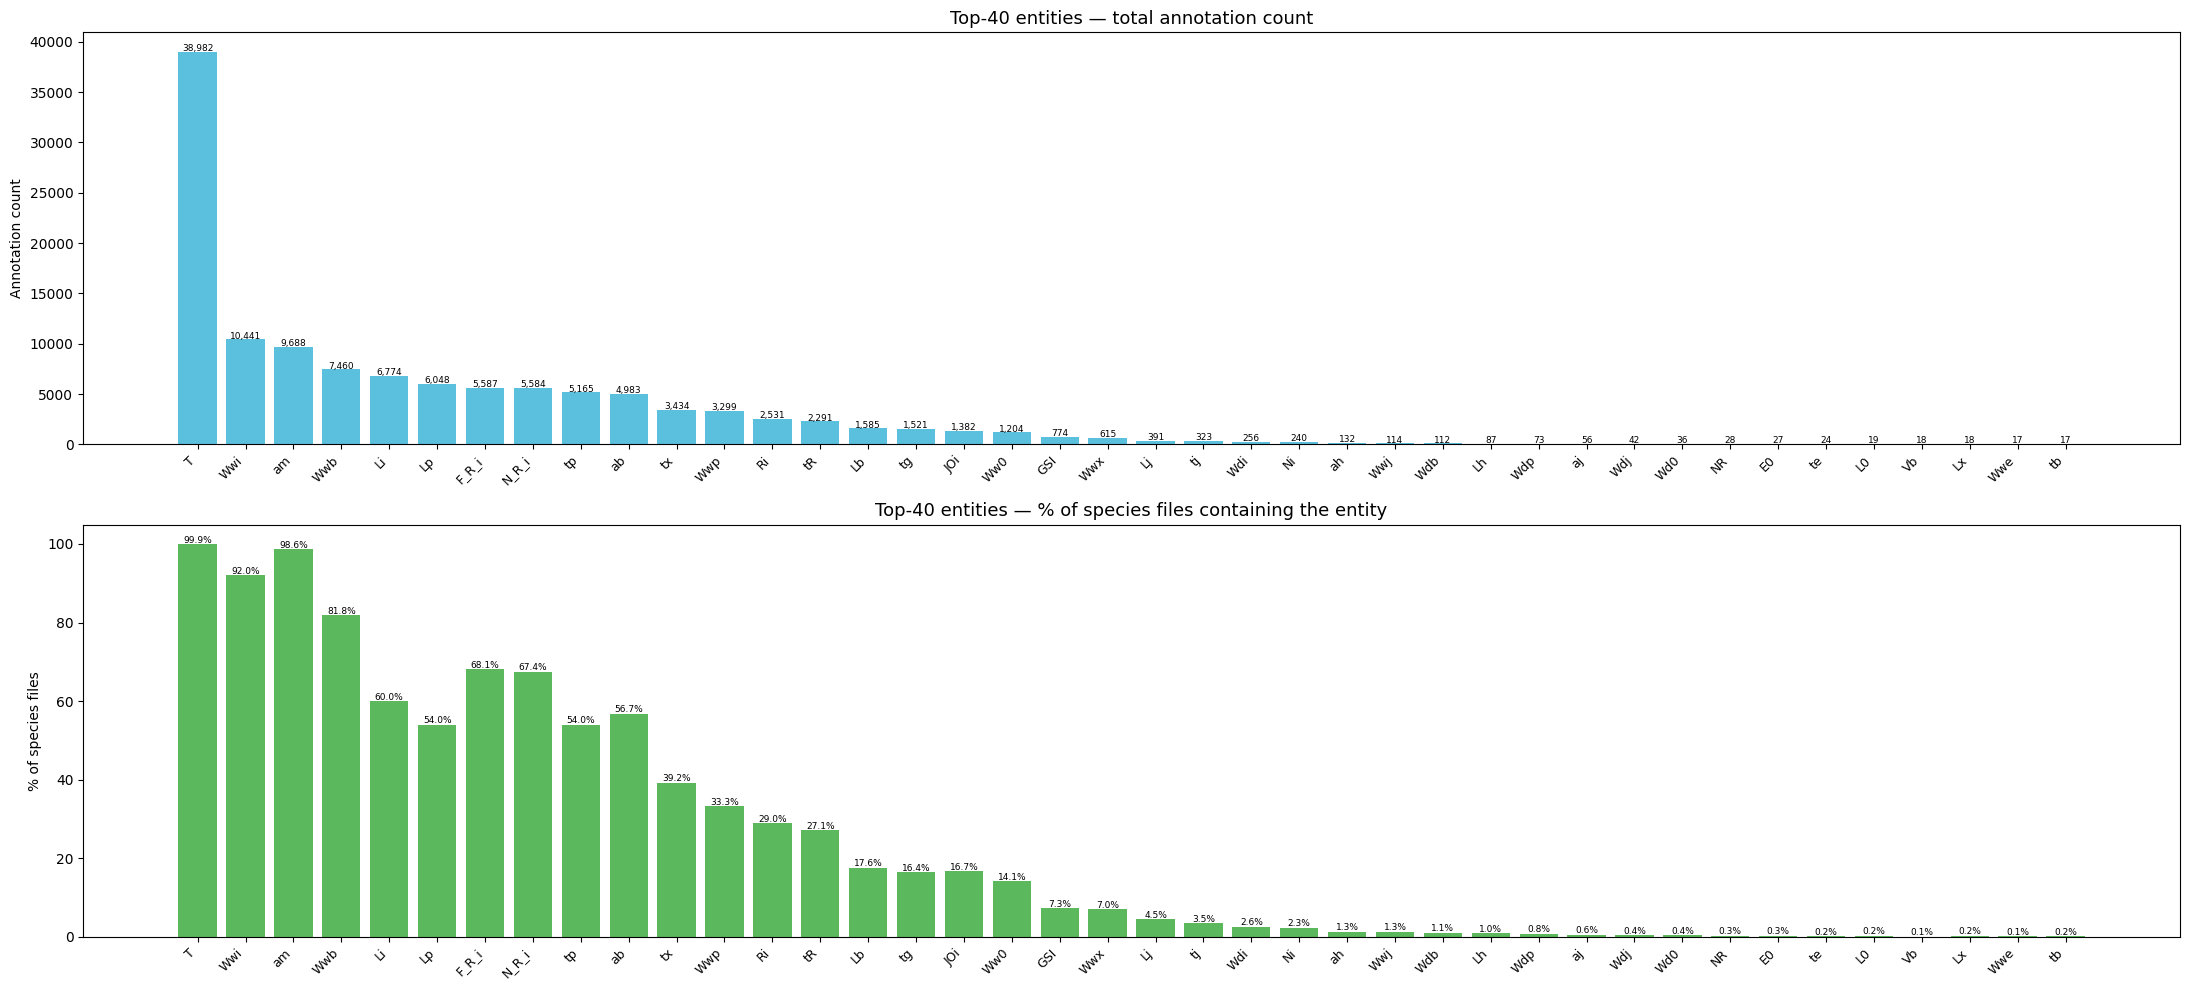

,entity,count,n_files,% of total annotations,% of files
rank,,,,,
1,T,38982,7271,31.93,99.86
2,Wwi,10441,6696,8.55,91.97
3,am,9688,7181,7.94,98.63
4,Wwb,7460,5957,6.11,81.82
5,Li,6774,4367,5.55,59.98
6,Lp,6048,3932,4.95,54.00
7,F_R_i,5587,4960,4.58,68.12
8,N_R_i,5584,4910,4.57,67.44
9,tp,5165,3929,4.23,53.96


In [2]:
import matplotlib.pyplot as plt
import numpy as np

df_top40 = df_entities.head(40).copy()

# --- printed table ---
print(f"{'Rank':>4}  {'Entity':<22} {'Count':>8}  {'Files':>6}  {'% annot':>8}  {'% files':>8}")
print("-" * 64)
for _, row in df_top40.iterrows():
    print(f"{int(row['rank']):>4}  {row['entity']:<22} {int(row['count']):>8,}  "
          f"{int(row['n_files']):>6,}  {row['% of total annotations']:>7.2f}%  {row['% of files']:>7.2f}%")

# --- chart: annotation count (top) + % of files (bottom) ---
x = np.arange(len(df_top40))
labels = df_top40["entity"].tolist()

fig, axes = plt.subplots(2, 1, figsize=(22, 10))

axes[0].bar(x, df_top40["count"], color="#5bc0de")
axes[0].set_title("Top-40 entities — total annotation count", fontsize=13)
axes[0].set_ylabel("Annotation count")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
for i, v in enumerate(df_top40["count"]):
    axes[0].text(i, v + 80, f"{v:,}", ha="center", fontsize=6.5)

axes[1].bar(x, df_top40["% of files"], color="#5cb85c")
axes[1].set_title("Top-40 entities — % of species files containing the entity", fontsize=13)
axes[1].set_ylabel("% of species files")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
for i, v in enumerate(df_top40["% of files"]):
    axes[1].text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=6.5)

plt.tight_layout()
plt.show()

# --- dataframe view ---
df_top40.set_index("rank", inplace=True)
df_top40

/var/folders/zd/m7n1ck0972db281qpws703hm0000gn/T/ipykernel_29373/2302636889.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap   = cm.get_cmap("tab20", 40)


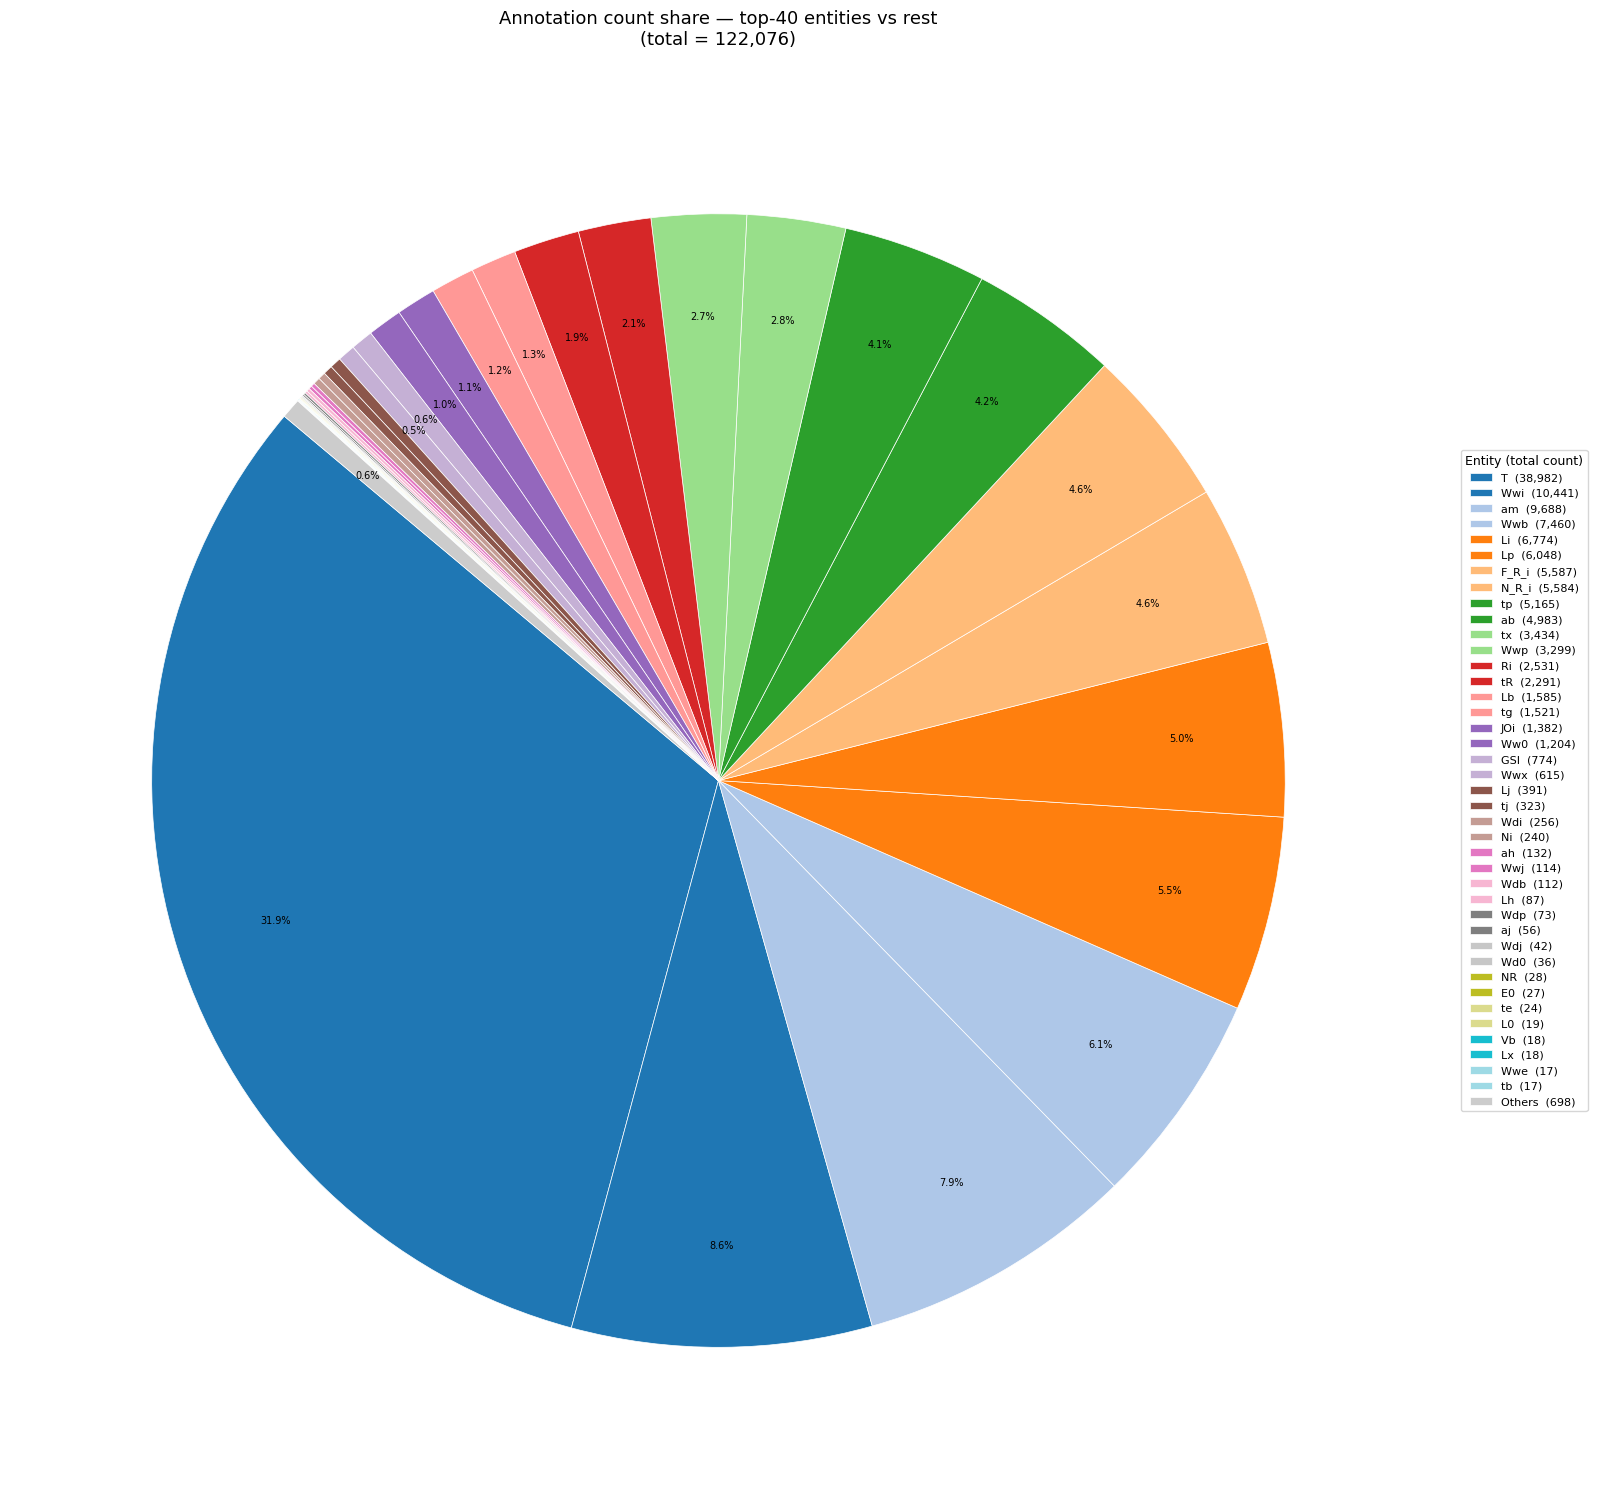

In [4]:
# Pie chart — share of each top-40 entity in total annotation count
# (remaining 308 entities grouped as "Others")

df_top40_pie = df_entities.head(40).copy()
others_count = total_ann - df_top40_pie["count"].sum()

labels_pie = df_top40_pie["entity"].tolist() + ["Others"]
sizes_pie  = df_top40_pie["count"].tolist() + [others_count]

# Colour palette: 40 distinct colours + grey for Others
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

cmap   = cm.get_cmap("tab20", 40)
colors = [cmap(i) for i in range(40)] + ["#cccccc"]

fig, ax = plt.subplots(figsize=(16, 16))
wedges, texts, autotexts = ax.pie(
    sizes_pie,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p >= 0.5 else "",
    colors=colors,
    startangle=140,
    pctdistance=0.82,
    wedgeprops={"linewidth": 0.5, "edgecolor": "white"},
)
for at in autotexts:
    at.set_fontsize(7)

ax.legend(
    wedges,
    [f"{l}  ({c:,})" for l, c in zip(labels_pie, sizes_pie)],
    title="Entity (total count)",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=8,
    title_fontsize=9,
)
ax.set_title(
    f"Annotation count share — top-40 entities vs rest\n(total = {total_ann:,})",
    fontsize=13, pad=20
)
plt.tight_layout()
plt.show()

In [5]:
import shutil

# Top-20 entity keys (ranked by total count)
TOP20 = [k for k, _ in entity_counter.most_common(20)]
print("Keeping annotations for:", TOP20)

# Regex: matches [KEY = ...] where KEY is NOT in TOP20
# Built as a negative-lookahead pattern so we remove any [X = ...] where X is outside top-20
top20_set = set(TOP20)

def strip_non_top20(text):
    """Remove every [KEY = value] span whose KEY is not in top20_set."""
    def replace(m):
        key_match = KEY_PATTERN.match(m.group(0))
        if key_match and key_match.group(1) in top20_set:
            return m.group(0)   # keep
        return ""               # delete
    return ANN_PATTERN.sub(replace, text)

# Output folder
out_dir = Path("../all_species_json_top20")
out_dir.mkdir(exist_ok=True)

processed  = 0
ann_before = 0
ann_after  = 0

for f in sorted(base_dir.iterdir()):
    if f.suffix != ".json":
        continue
    data = json.loads(f.read_text())
    original_text = data.get("corrected_text_final", "")

    # Count before
    keys_before = [m.group(1) for a in ANN_PATTERN.findall(original_text)
                   for m in [KEY_PATTERN.match(a)] if m]
    ann_before += len(keys_before)

    # Clean
    cleaned_text = strip_non_top20(original_text)

    # Count after
    keys_after = [m.group(1) for a in ANN_PATTERN.findall(cleaned_text)
                  for m in [KEY_PATTERN.match(a)] if m]
    ann_after += len(keys_after)

    data["corrected_text_final"] = cleaned_text
    (out_dir / f.name).write_text(json.dumps(data, indent=2, ensure_ascii=False))
    processed += 1

print(f"\nFiles processed        : {processed:,}")
print(f"Annotations before     : {ann_before:,}")
print(f"Annotations after      : {ann_after:,}")
print(f"Annotations removed    : {ann_before - ann_after:,}")
print(f"Output folder          : {out_dir.resolve()}")

Keeping annotations for: ['T', 'Wwi', 'am', 'Wwb', 'Li', 'Lp', 'F_R_i', 'N_R_i', 'tp', 'ab', 'tx', 'Wwp', 'Ri', 'tR', 'Lb', 'tg', 'JOi', 'Ww0', 'GSI', 'Wwx']

Files processed        : 7,281
Annotations before     : 122,076
Annotations after      : 119,348
Annotations removed    : 2,728
Output folder          : /Users/somaya/Documents/Phd/github_version/version_2/deb-data-pipeline-github/data_verification/all_species_json_top20


Folder                     : all_species_json_top20
Total species files        : 7,281
Total annotation instances : 119,348
Unique entity types        : 20

Rank  Entity                    Count   Files   % annot   % files
----------------------------------------------------------------
   1  T                        38,982   7,271    32.66%    99.86%
   2  Wwi                      10,441   6,696     8.75%    91.97%
   3  am                        9,688   7,181     8.12%    98.63%
   4  Wwb                       7,460   5,957     6.25%    81.82%
   5  Li                        6,774   4,367     5.68%    59.98%
   6  Lp                        6,048   3,932     5.07%    54.00%
   7  F_R_i                     5,587   4,960     4.68%    68.12%
   8  N_R_i                     5,584   4,910     4.68%    67.44%
   9  tp                        5,165   3,929     4.33%    53.96%
  10  ab                        4,983   4,131     4.18%    56.74%
  11  tx                        3,434   2,858     2.

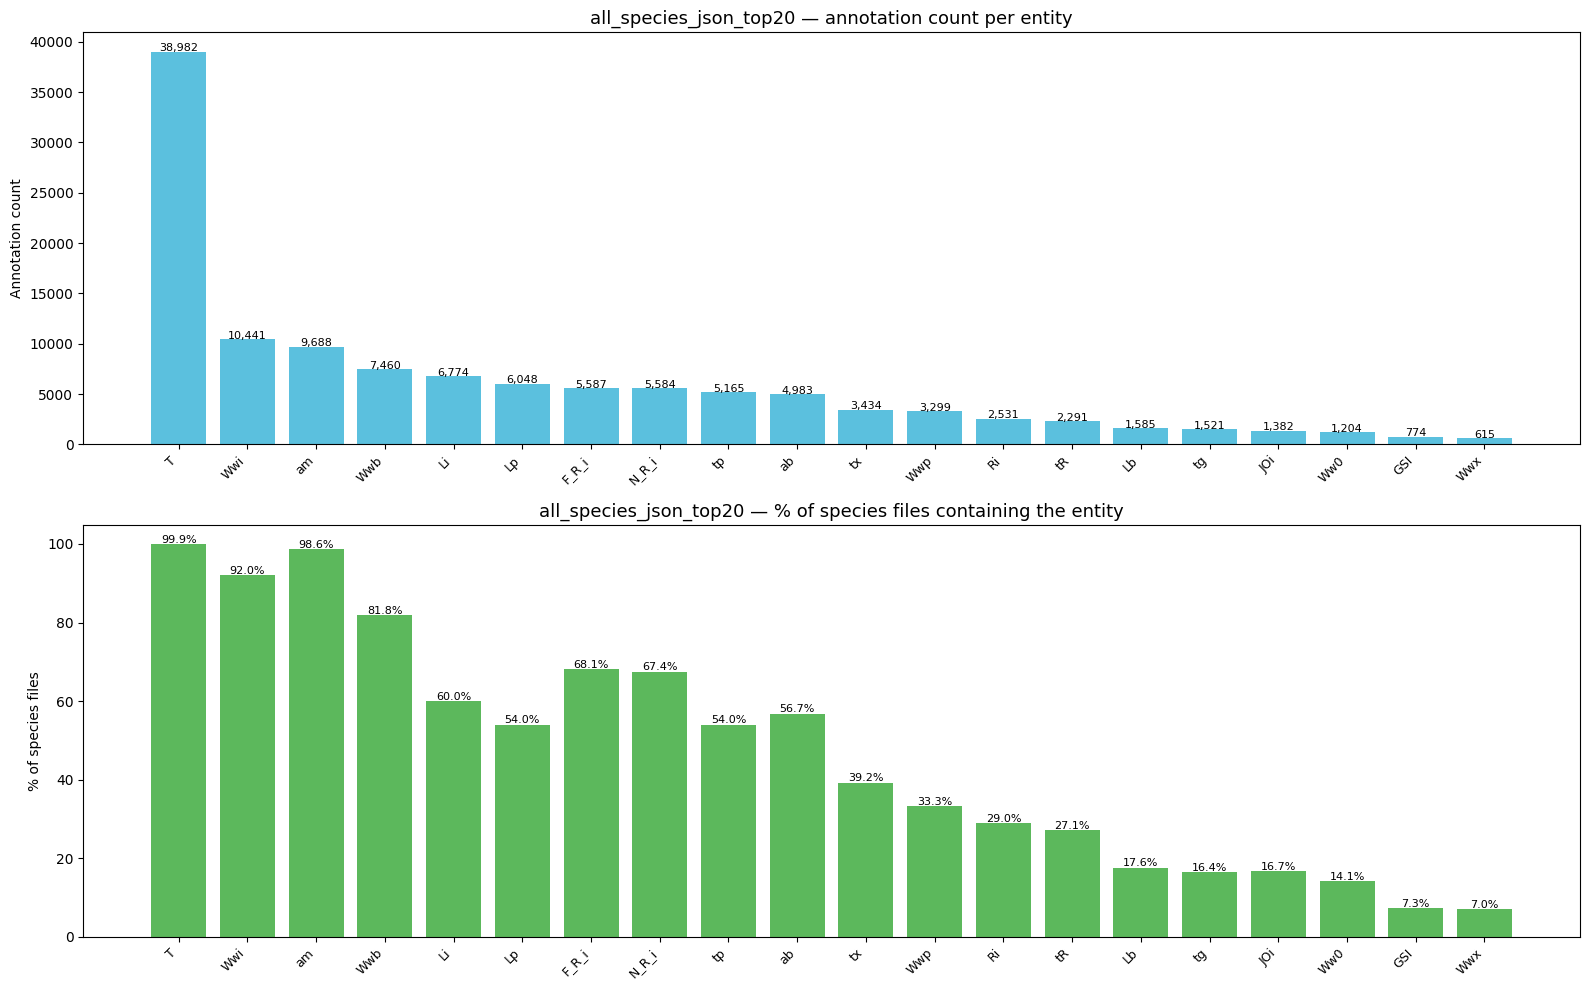

,entity,count,n_files,% of total annotations,% of files
rank,,,,,
1,T,38982,7271,32.66,99.86
2,Wwi,10441,6696,8.75,91.97
3,am,9688,7181,8.12,98.63
4,Wwb,7460,5957,6.25,81.82
5,Li,6774,4367,5.68,59.98
6,Lp,6048,3932,5.07,54.00
7,F_R_i,5587,4960,4.68,68.12
8,N_R_i,5584,4910,4.68,67.44
9,tp,5165,3929,4.33,53.96


In [6]:
# Statistics of entities in all_species_json_top20
new_dir = Path("../all_species_json_top20")

new_entity_counter = Counter()
new_entity_files   = defaultdict(int)
new_total_ann      = 0

for f in sorted(new_dir.iterdir()):
    if f.suffix != ".json":
        continue
    text = json.loads(f.read_text()).get("corrected_text_final", "")
    keys = [m.group(1) for a in ANN_PATTERN.findall(text) for m in [KEY_PATTERN.match(a)] if m]
    new_entity_counter.update(keys)
    for k in set(keys):
        new_entity_files[k] += 1
    new_total_ann += len(keys)

new_total_files = len(list(new_dir.glob("*.json")))

df_new = pd.DataFrame([
    {
        "rank":                   i + 1,
        "entity":                 k,
        "count":                  c,
        "n_files":                new_entity_files[k],
        "% of total annotations": round(c / new_total_ann * 100, 2),
        "% of files":             round(new_entity_files[k] / new_total_files * 100, 2),
    }
    for i, (k, c) in enumerate(new_entity_counter.most_common())
])

print(f"Folder                     : all_species_json_top20")
print(f"Total species files        : {new_total_files:,}")
print(f"Total annotation instances : {new_total_ann:,}")
print(f"Unique entity types        : {len(new_entity_counter)}")
print()

# Printed table
print(f"{'Rank':>4}  {'Entity':<22} {'Count':>8}  {'Files':>6}  {'% annot':>8}  {'% files':>8}")
print("-" * 64)
for _, row in df_new.iterrows():
    print(f"{int(row['rank']):>4}  {row['entity']:<22} {int(row['count']):>8,}  "
          f"{int(row['n_files']):>6,}  {row['% of total annotations']:>7.2f}%  {row['% of files']:>7.2f}%")

# Bar charts
x      = np.arange(len(df_new))
labels = df_new["entity"].tolist()

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

axes[0].bar(x, df_new["count"], color="#5bc0de")
axes[0].set_title("all_species_json_top20 — annotation count per entity", fontsize=13)
axes[0].set_ylabel("Annotation count")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
for i, v in enumerate(df_new["count"]):
    axes[0].text(i, v + 60, f"{v:,}", ha="center", fontsize=8)

axes[1].bar(x, df_new["% of files"], color="#5cb85c")
axes[1].set_title("all_species_json_top20 — % of species files containing the entity", fontsize=13)
axes[1].set_ylabel("% of species files")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
for i, v in enumerate(df_new["% of files"]):
    axes[1].text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

df_new.set_index("rank")